# IoT Botnet Traffic Classifier

**Lab 3 — Cybersecurity & Machine Learning (Team Project), Topic 4**

This notebook covers the **Data & Model Pipeline** (Step 1: data preparation,
Step 2: model training/evaluation) and the **Live Defense evasion test**
(Step 4) for the IoT Botnet Traffic Classifier project. It reuses the same
`src/` modules the project's `train.py` script and `app.py` Streamlit
dashboard both import, so every result here is identical to what those
produce — this notebook just adds inline narration and visualization.

**Step 3 (the Streamlit web app) is not a notebook step** — dashboards are
interactive web apps, not notebook cells. Run it separately with:
```bash
streamlit run app.py
```

**Team members:** `[ENTER NAME 1]`, `[ENTER NAME 2]`


## Setup

Import the project's own pipeline modules (`src/config.py`,
`src/data_loader.py`, `src/preprocessing.py`) so this notebook and
`train.py`/`app.py` can never drift apart.


In [1]:
%matplotlib inline
import sys, os
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix)

from src import config, data_loader, preprocessing

pd.set_option("display.max_columns", 40)
sns.set_style("whitegrid")


## Step 1 — Data Loading & Exploration

Downloads (on first run) and loads the CICIDS2017 Friday-Afternoon DDoS
capture — real, labeled network flow records. See `README.md` for why this
dataset is used instead of N-BaIoT/Bot-IoT (both unreachable from this
project's development sandbox).


In [2]:
df = data_loader.load_raw_data()
print(f"Raw flow records: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[config.LABEL_COLUMN].value_counts()


Raw flow records: 225,745 rows x 32 columns


Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

In [3]:
numeric = df.select_dtypes(include=[np.number])
print(f"Infinite values: {int(np.isinf(numeric).sum().sum())}")
print(f"Missing (NaN) values: {int(df.isna().sum().sum())}")
df.head()


Infinite values: 0
Missing (NaN) values: 4


,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Label
0,104.16.207.165,443,192.168.10.5,54865,6,07/07/2017 03:30,3,2,0,12,0,4.000000e+06,666666.66670,0,0,0,0,40,0,666666.666700,0.000000,6,6,0,0,0,0,1,0,0,0,BENIGN
1,104.16.28.216,80,192.168.10.5,55054,6,07/07/2017 03:30,109,1,1,6,6,1.100917e+05,18348.62385,0,0,0,0,20,20,9174.311927,9174.311927,6,6,0,0,0,0,1,1,0,0,BENIGN
2,104.16.28.216,80,192.168.10.5,55055,6,07/07/2017 03:30,52,1,1,6,6,2.307692e+05,38461.53846,0,0,0,0,20,20,19230.769230,19230.769230,6,6,0,0,0,0,1,1,0,0,BENIGN
3,104.17.241.25,443,192.168.10.16,46236,6,07/07/2017 03:30,34,1,1,6,6,3.529412e+05,58823.52941,0,0,0,0,20,20,29411.764710,29411.764710,6,6,0,0,0,0,1,1,0,0,BENIGN
4,104.19.196.102,443,192.168.10.5,54863,6,07/07/2017 03:30,3,2,0,12,0,4.000000e+06,666666.66670,0,0,0,0,40,0,666666.666700,0.000000,6,6,0,0,0,0,1,0,0,0,BENIGN


## Step 1b — Data Cleaning & Feature Preparation

- Drops `Source IP` / `Source Port` / `Destination IP` / `Destination Port`
  / `Timestamp` — host/port/time metadata that would let the model key off
  this one capture's specific setup instead of learning general flow
  behavior.
- Treats infinite values (a CICFlowMeter quirk on near-zero-duration flows)
  as missing and drops incomplete rows.
- Binarizes the label: `1` = DDoS, `0` = BENIGN.
- Stratified 70/30 train/test split.


In [4]:
X_train, X_test, y_train, y_test, feature_names = preprocessing.prepare(df)

print(f"Features ({len(feature_names)}): {feature_names}")
print(f"\nTraining set: {len(X_train):,} flows "
      f"({(y_train == 1).sum():,} threat, {(y_train == 0).sum():,} safe)")
print(f"Testing set:  {len(X_test):,} flows "
      f"({(y_test == 1).sum():,} threat, {(y_test == 0).sum():,} safe)")
X_train.head()


Features (26): ['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count']

Training set: 158,018 flows (89,619 threat, 68,399 safe)
Testing set:  67,723 flows (38,408 threat, 29,315 safe)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count
221269,17,50698,1,1,48,88,2682.551580,39.449288,0,0,0,0,32,32,19.724644,19.724644,48,88,0,0,0,0,0,0,0,0
97495,6,19847,3,5,26,11601,585831.611800,403.083590,0,0,0,0,72,112,151.156346,251.927243,0,5840,0,0,0,1,0,0,0,0
111417,6,8443804,1,5,6,30,4.263481,0.710580,0,0,0,0,20,100,0.118430,0.592150,6,6,0,0,0,0,1,1,0,0
118727,6,58226,3,5,26,11601,199687.424900,137.395665,0,0,0,0,72,112,51.523374,85.872291,0,4380,0,0,0,1,0,0,0,0
3834,6,49935,1,1,0,0,0.000000,40.052068,0,0,0,0,32,32,20.026034,20.026034,0,0,0,0,0,0,1,1,0,0


## Step 2 — Model Training (Random Forest)

`RandomForestClassifier` — recommended by the assignment. No feature
scaling is applied, since tree splits are scale-invariant.


In [5]:
N_ESTIMATORS = 200
model = RandomForestClassifier(
    n_estimators=N_ESTIMATORS, random_state=config.RANDOM_STATE, n_jobs=-1,
)
model.fit(X_train, y_train)
print(f"Trained RandomForestClassifier(n_estimators={N_ESTIMATORS}) "
      f"on {len(X_train):,} labeled flows.")


Trained RandomForestClassifier(n_estimators=200) on 158,018 labeled flows.


### Evaluation

In [6]:
y_pred = model.predict(X_test)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "f1_score": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
}
pd.Series(metrics, name="value").to_frame()


,value
accuracy,0.999631
precision,0.999818
recall,0.999531
f1_score,0.999675


TN=29,308  FP=7  FN=18  TP=38,390


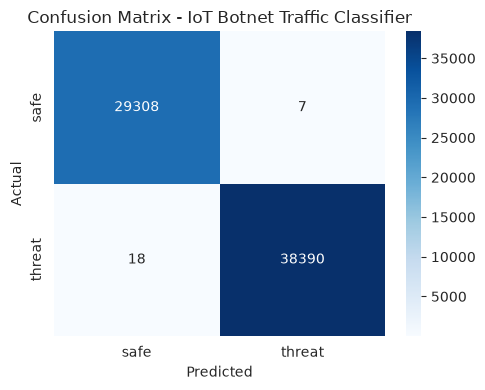

In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["safe", "threat"], yticklabels=["safe", "threat"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - IoT Botnet Traffic Classifier")
plt.tight_layout()
plt.show()


This near-perfect score is expected: CICIDS2017's Friday DDoS is a
**volumetric flood**, so its attack flows are statistically very different
from benign traffic. That's exactly what makes the evasion test in Step 4
meaningful — the model is genuinely excellent at catching *this* kind of
attack, and the interesting question is what kind of attack it *isn't*
good at catching.

### Feature importance


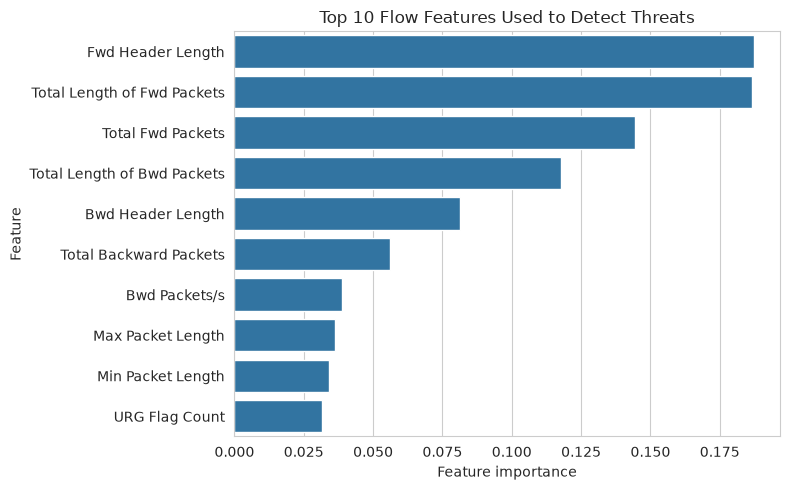

,importance
Fwd Header Length,0.187344
Total Length of Fwd Packets,0.186472
Total Fwd Packets,0.144283
Total Length of Bwd Packets,0.117817
Bwd Header Length,0.081282
Total Backward Packets,0.056165
Bwd Packets/s,0.038853
Max Packet Length,0.036329
Min Packet Length,0.034010
URG Flag Count,0.031518


In [8]:
importances = pd.Series(model.feature_importances_, index=feature_names)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, color="tab:blue")
plt.xlabel("Feature importance"); plt.ylabel("Feature")
plt.title("Top 10 Flow Features Used to Detect Threats")
plt.tight_layout()
plt.show()

top10.to_frame("importance")


`Fwd Header Length` and `Total Length of Fwd Packets` dominate — a flood
attack pushes far more packets and far more total bytes through a
connection than normal traffic does in the same window, and header length
scales directly with packet count. The model has essentially learned
**"how much traffic moved through this connection"** — the single
strongest signal a volumetric DDoS leaves behind.

### Save the model bundle

`app.py` loads this exact file — the fitted model, the feature-column
list, and the test metrics — so the dashboard reproduces identical
preprocessing at inference time.


In [9]:
import joblib

os.makedirs(config.MODELS_DIR, exist_ok=True)
bundle = {
    "model": model,
    "feature_names": feature_names,
    "metrics": metrics,
    "n_estimators": N_ESTIMATORS,
    "training_rows": len(X_train),
}
joblib.dump(bundle, config.MODEL_PATH)
print(f"Saved model bundle to {config.MODEL_PATH}")


Saved model bundle to /home/user/pythonAI/Lab3/models/iot_botnet_model.pkl


## Step 4 — Live Defense: Evasion Test

**Attack case:** `data/low_and_slow_evasion.csv` — 40 hand-crafted flow
records simulating a **low-and-slow DDoS** (Slowloris-style): each one
holds a connection open for 60–180 seconds while trickling only 3–8 tiny
packets total, instead of moving a lot of data quickly (see
`scripts/make_evasion_set.py` for the full reasoning). This is the
self-attack input used in the live presentation demo — the same file can
be uploaded directly in the Streamlit dashboard.


In [10]:
evasion_raw = pd.read_csv(config.EVASION_CSV_PATH)
X_evasion = preprocessing.transform_for_inference(evasion_raw, feature_names)

evasion_proba = model.predict_proba(X_evasion)[:, 1]
evasion_pred = (evasion_proba >= 0.5).astype(int)

results = evasion_raw.copy()
results["Threat Probability"] = evasion_proba.round(4)
results["Verdict"] = np.where(evasion_pred == 1, "Threat", "Safe")

n_evaded = int((evasion_pred == 0).sum())
print(f"Evasion rows: {len(results)}")
print(f"Flagged as Threat: {(evasion_pred == 1).sum()}   "
      f"Flagged as Safe (evaded): {n_evaded}")
print(f"Threat-probability range: {evasion_proba.min():.3f} - {evasion_proba.max():.3f}")

results[["Source IP", "Flow Duration", "Total Fwd Packets", "Flow Bytes/s",
         "Flow Packets/s", "Threat Probability", "Verdict"]].head(15)


Evasion rows: 40
Flagged as Threat: 0   Flagged as Safe (evaded): 40
Threat-probability range: 0.025 - 0.435


,Source IP,Flow Duration,Total Fwd Packets,Flow Bytes/s,Flow Packets/s,Threat Probability,Verdict
0,192.168.1.17,152874725,8,0.928865,0.058872,0.070,Safe
1,192.168.1.39,112665412,5,1.260369,0.062131,0.085,Safe
2,192.168.1.14,163031750,3,0.558173,0.024535,0.205,Safe
3,192.168.1.42,143684163,7,0.716850,0.055678,0.265,Safe
4,192.168.1.41,71301281,6,1.248224,0.112200,0.200,Safe
5,192.168.1.14,177074682,7,0.666385,0.045179,0.110,Safe
6,192.168.1.47,151336764,3,0.647562,0.019823,0.370,Safe
7,192.168.1.30,154327716,4,0.615573,0.038878,0.395,Safe
8,192.168.1.49,75373635,7,0.915439,0.106138,0.390,Safe
9,192.168.1.12,114046312,7,0.605017,0.070147,0.335,Safe


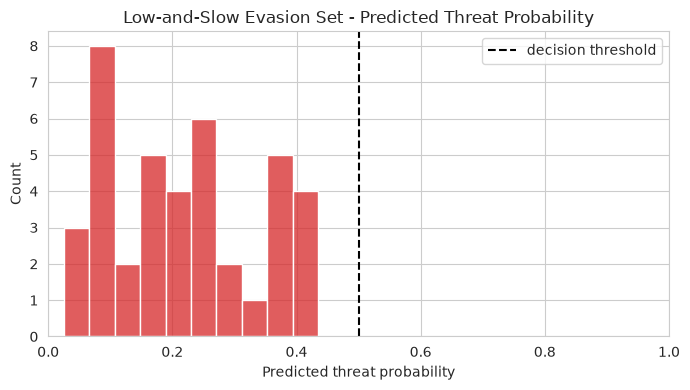

In [11]:
plt.figure(figsize=(7, 4))
sns.histplot(evasion_proba, bins=10, color="tab:red")
plt.axvline(0.5, color="black", linestyle="--", label="decision threshold")
plt.xlim(0, 1)
plt.xlabel("Predicted threat probability")
plt.title("Low-and-Slow Evasion Set - Predicted Threat Probability")
plt.legend()
plt.tight_layout()
plt.show()


### Result: 40/40 evaded — 100% false negatives

Every crafted row is classified **Safe**. **Why it works:** the model
learned that "threat" looks like *a lot of traffic moving through a
connection* (see feature importance above). A low-and-slow attack is
specifically engineered to avoid that footprint — few packets, few bytes,
spread across a long duration — so its flow statistics land in a region of
feature space the model has no attack examples for at all. This is a
**training-data blind spot**, not a bug in the model or the code.

**How to improve it** (see `README.md` §8 for the full write-up):
1. Add rate/behavioral features meaningful only in aggregate (e.g.
   connections-per-source-IP over a sliding time window) — a single
   low-and-slow flow looks idle, but a coordinated botnet running
   thousands of them simultaneously is not, a pattern invisible at the
   single-flow level this model operates on.
2. Retrain with labeled low-and-slow examples once available.
3. Add a duration/throughput rule as an interim stopgap.

## Conclusion

The Random Forest classifier is extremely effective against the volumetric
DDoS pattern it was trained on (99.96% accuracy, 99.95% recall on the real
CICIDS2017 test set) — but the live self-attack test proves that
effectiveness is narrower than the headline metrics suggest: a low-and-slow
attack, deliberately engineered to avoid the exact footprint the model
learned, evades detection 100% of the time. A classifier can only be as
good as the behavioral signal present in the features and training
examples it is given.
